<a href="https://colab.research.google.com/github/samueladian3-cpu/ml-portfolio/blob/main/%5BClustering%5D_Submission_Akhir_BMLP_Samuel_Adian.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Penting**
- Jangan menambahkan import library atau function apa pun, selain yang sudah tersedia pada cell code atau yang diperbolehkan.
- Jangan mengubah atau menambahkan cell text yang sudah disediakan, Anda hanya perlu mengerjakan cell code yang sudah disediakan.
- Pastikan seluruh kriteria memiliki output yang sesuai, karena jika tidak ada output dianggap tidak selesai.
- Pastikan Anda melakukan Run All sebelum mengirimkan submission untuk memastikan seluruh cell berjalan dengan baik.
- Pastikan Anda menggunakan variabel df dari awal sampai akhir dan tidak diperbolehkan mengganti nama variabel tersebut.

# **1. Import Library**
Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer
import joblib
import warnings
warnings.filterwarnings('ignore')

# **2. Memuat Dataset**
Memuat dataset ke dalam DataFrame.

In [ ]:
# Load data

### MULAI CODE ###

df = pd.read_csv('bank_transactions_data_edited.csv')

### SELESAI CODE ###

In [ ]:
# Tampilkan 5 baris pertama dengan function head.

### MULAI CODE ###

df.head()

### SELESAI CODE ###

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 08:06:39


In [ ]:
# Tinjau jumlah baris kolom dan jenis data dalam dataset dengan info.

### MULAI CODE ###

df.info()

### SELESAI CODE ###

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   TransactionDate          2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [ ]:
# Menampilkan statistik deskriptif dataset dengan menjalankan describe

### MULAI CODE ###

df.describe(include='all')

### SELESAI CODE ###

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
count,2508,2516,2511.000000,2509,2507,2507,2507,2517,2514,2510,2519.000000,2514,2511.000000,2516.000000,2510.000000,2513
unique,2484,495,NaN,2485,2,43,681,591,100,3,NaN,4,NaN,NaN,NaN,360
top,TX001748,AC00362,NaN,2023-10-20 17:53:13,Debit,Fort Worth,D000573,200.136.146.93,M026,Branch,NaN,Student,NaN,NaN,NaN,2024-11-04 08:09:17
freq,2,12,NaN,2,1942,71,9,12,46,868,NaN,657,NaN,NaN,NaN,18
mean,NaN,NaN,297.656468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44.678444,NaN,119.422939,1.121622,5113.438124,NaN
std,NaN,NaN,292.230367,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.837359,NaN,70.078513,0.594469,3897.975861,NaN
min,NaN,NaN,0.260000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.000000,NaN,10.000000,1.000000,101.250000,NaN
25%,NaN,NaN,81.310000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.000000,NaN,63.000000,1.000000,1504.727500,NaN
50%,NaN,NaN,211.360000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.000000,NaN,112.000000,1.000000,4734.110000,NaN
75%,NaN,NaN,413.105000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.000000,NaN,161.000000,1.000000,7672.687500,NaN


## **Penilaian (Opsional)**

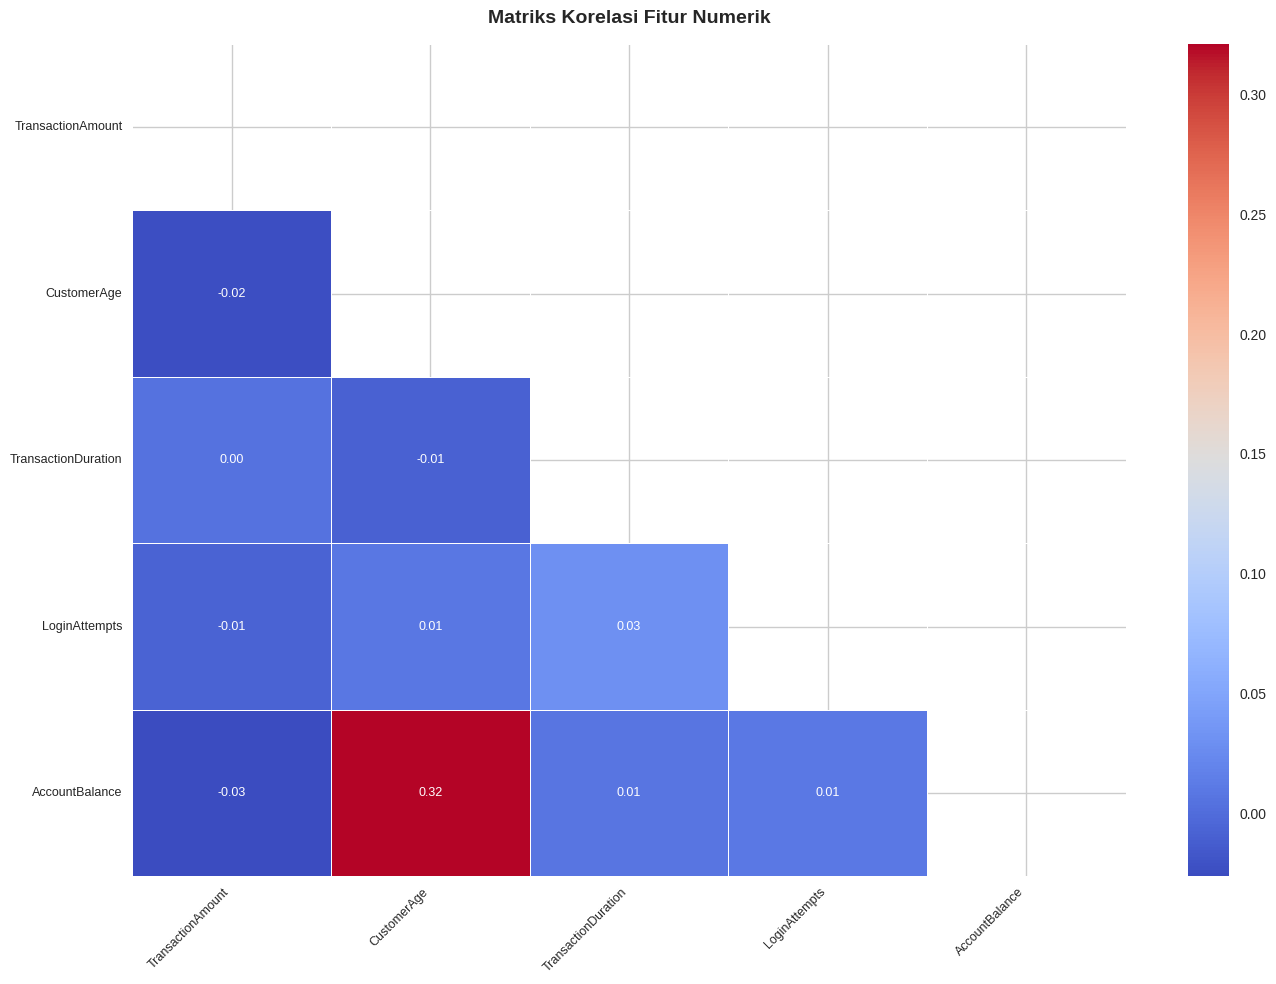

In [ ]:
# Menampilkan korelasi antar fitur (Opsional Skilled 1)

### MULAI CODE ###

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(14, 10))
corr_matrix = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    annot_kws={'size': 9}
)
plt.title('Matriks Korelasi Fitur Numerik', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

### SELESAI CODE ###

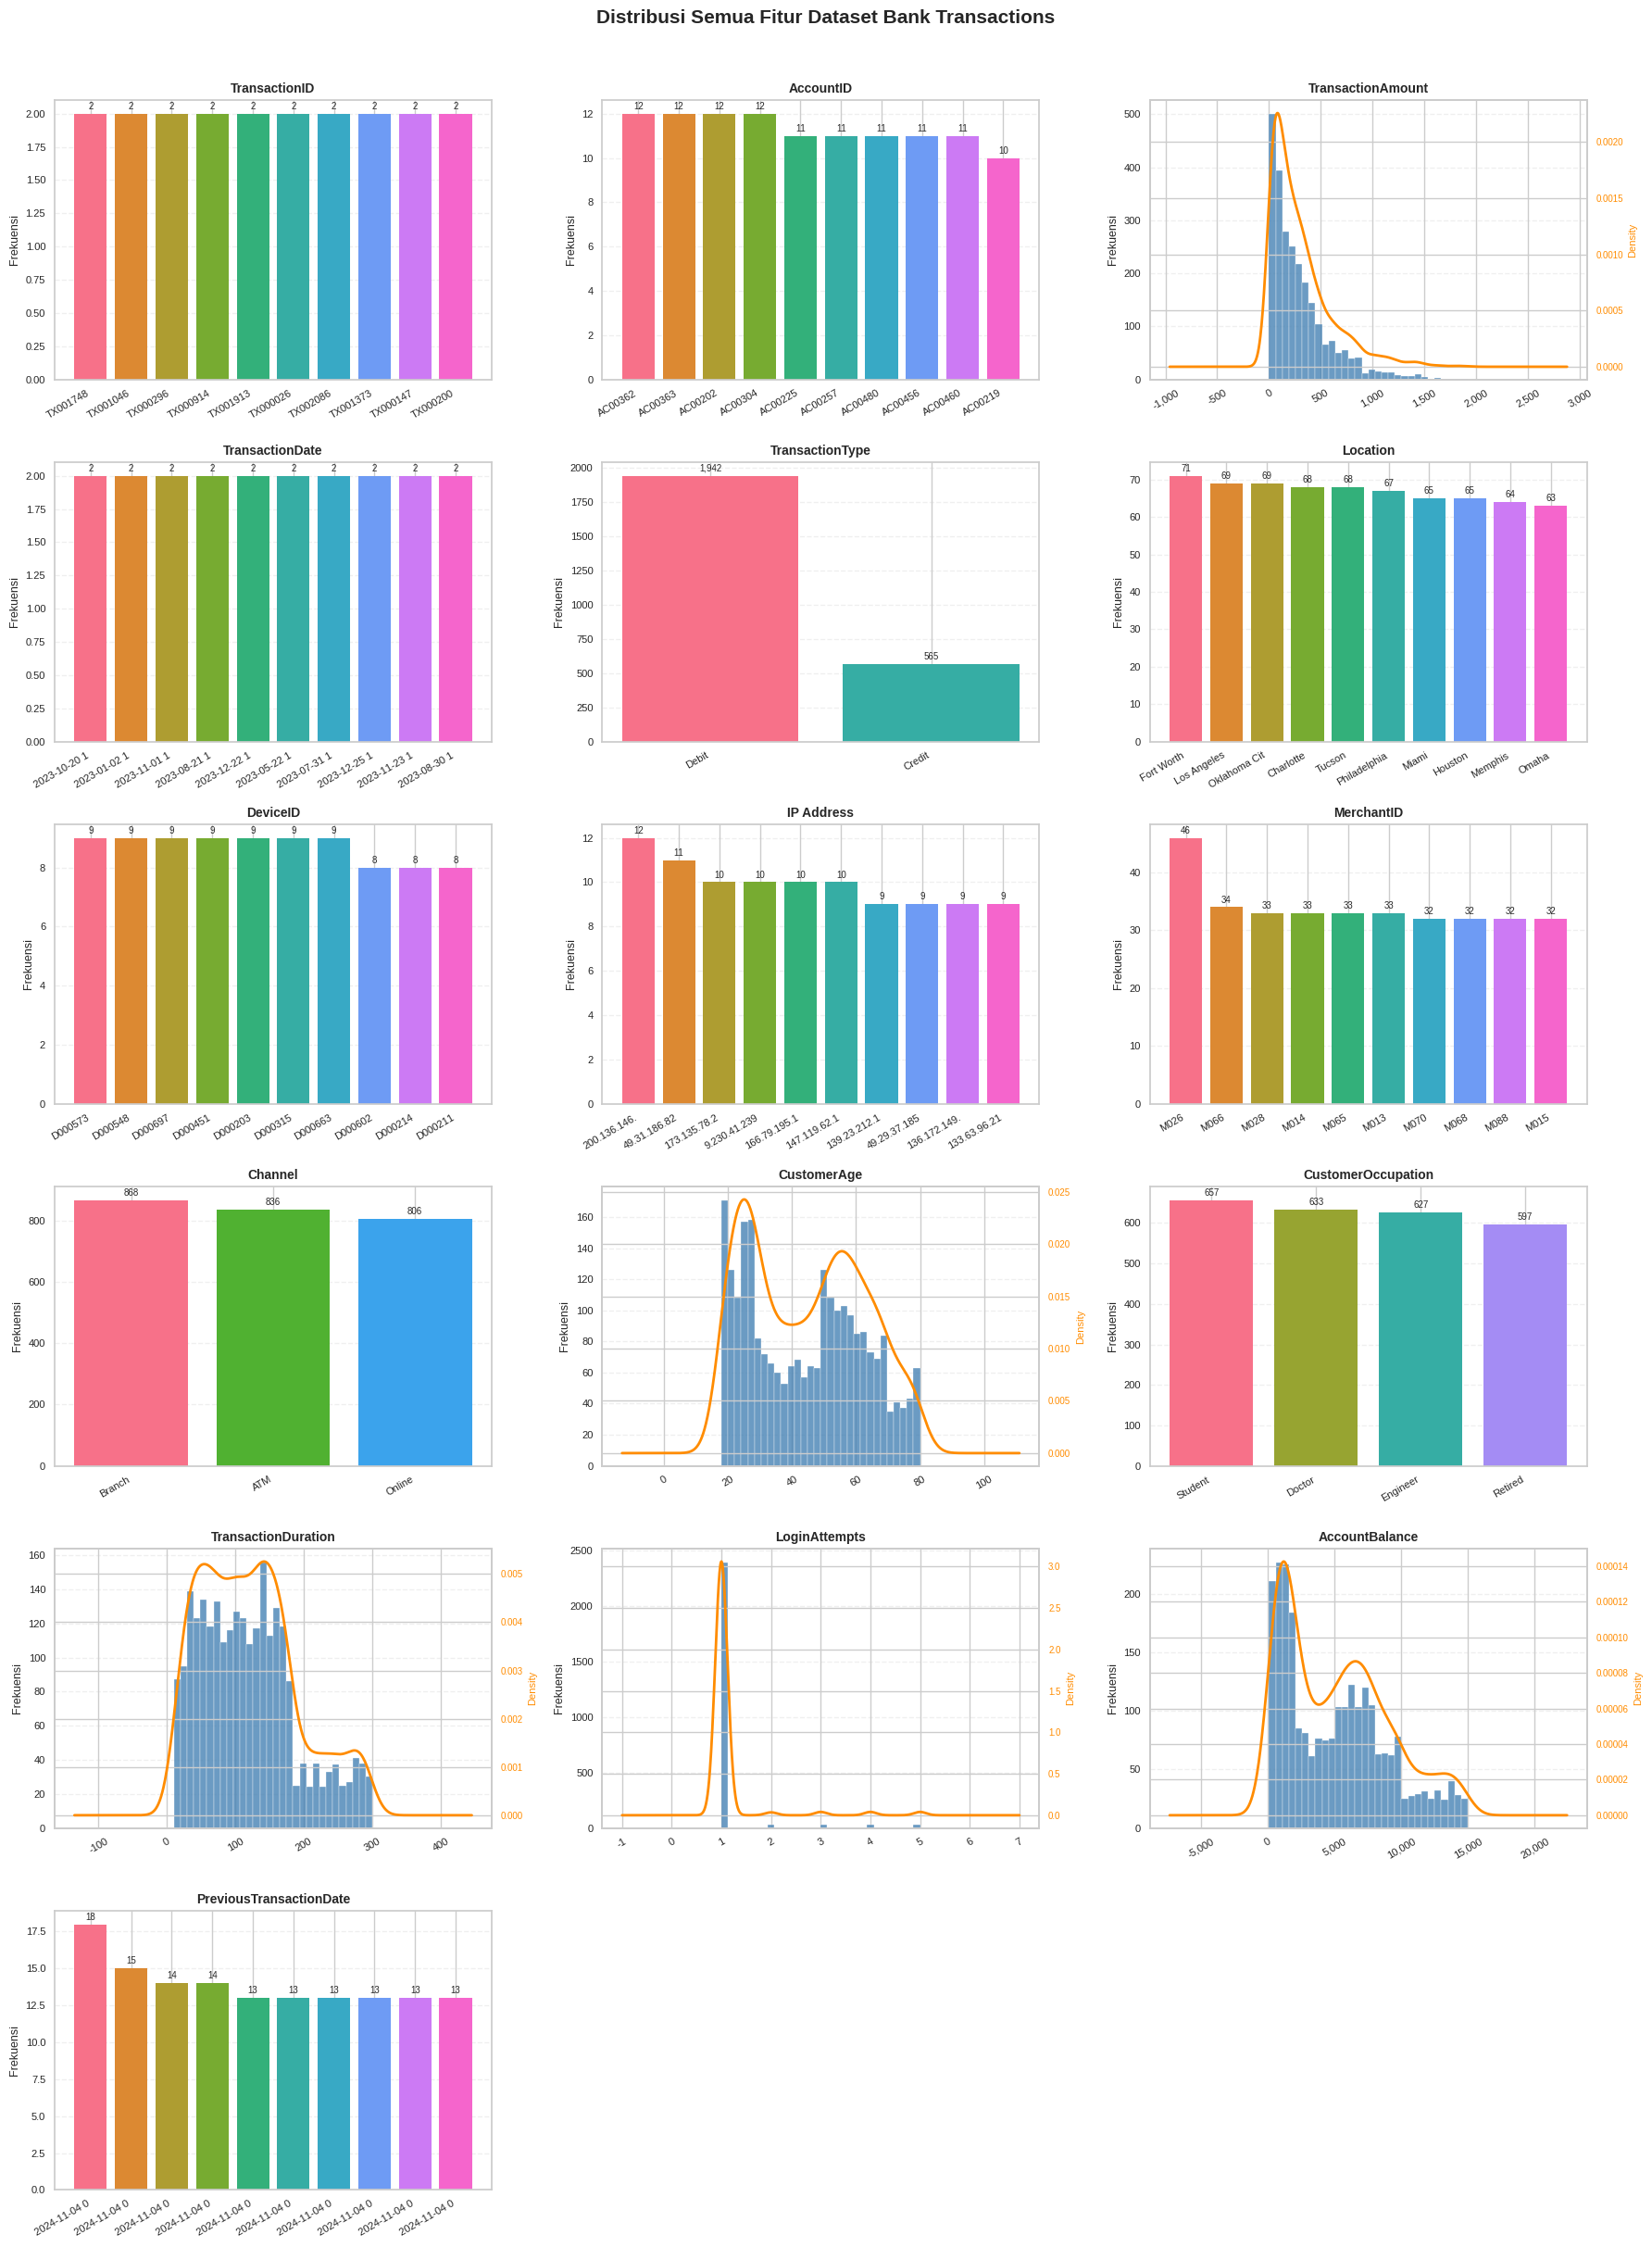

In [ ]:
# Menampilkan histogram untuk semua kolom dalam dataset (Opsional Skilled 1)
# Visualisasi yang lebih informatif tanpa label overlap (Opsional Advanced 1)

### MULAI CODE ###

all_cols = df.columns.tolist()
n_cols_grid = 3
n_rows_grid = (len(all_cols) + n_cols_grid - 1) // n_cols_grid

fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(18, n_rows_grid * 4))
axes = axes.flatten()

for i, col in enumerate(all_cols):
    ax = axes[i]
    if df[col].dtype == 'object':
        val_counts = df[col].value_counts().head(10)
        bars = ax.bar(range(len(val_counts)), val_counts.values,
                      color=sns.color_palette('husl', len(val_counts)))
        ax.set_xticks(range(len(val_counts)))
        ax.set_xticklabels(
            [str(v)[:12] for v in val_counts.index],
            rotation=30, ha='right', fontsize=8
        )
        ax.set_ylabel('Frekuensi', fontsize=9)
        for bar, val in zip(bars, val_counts.values):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + max(val_counts.values)*0.01,
                    f'{val:,}', ha='center', va='bottom', fontsize=7)
    else:
        ax.hist(df[col].dropna(), bins=30, color='steelblue', edgecolor='white', alpha=0.8)
        ax2 = ax.twinx()
        df[col].dropna().plot.kde(ax=ax2, color='darkorange', linewidth=2)
        ax2.set_ylabel('Density', fontsize=8, color='darkorange')
        ax2.tick_params(axis='y', labelcolor='darkorange', labelsize=7)
        ax.set_ylabel('Frekuensi', fontsize=9)
        ax.xaxis.set_major_formatter(
            ticker.FuncFormatter(lambda x, _: f'{x:,.0f}' if abs(x) < 1e6 else f'{x:.1e}')
        )
        ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.set_title(f'{col}', fontsize=10, fontweight='bold', pad=6)
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis='y', alpha=0.3, linestyle='--')

for j in range(len(all_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distribusi Semua Fitur Dataset Bank Transactions',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### SELESAI CODE ###

# **3. Pembersihan dan Pra Pemrosesan Data**
Mengecek, membersihkan, dan memproses data sebelum digunakan untuk clustering.

In [ ]:
# Mengecek dataset menggunakan isnull().sum()

### MULAI CODE ###

df.isnull().sum()

### SELESAI CODE ###

,0
TransactionID,29
AccountID,21
TransactionAmount,26
TransactionDate,28
TransactionType,30
Location,30
DeviceID,30
IP Address,20
MerchantID,23
Channel,27


In [ ]:
# Mengecek dataset menggunakan duplicated().sum()

### MULAI CODE ###

df.duplicated().sum()

### SELESAI CODE ###

np.int64(21)

In [ ]:
# Menangani data yang hilang.

### MULAI CODE ###

df = df.dropna()
df.isnull().sum()

### SELESAI CODE ###

,0
TransactionID,0
AccountID,0
TransactionAmount,0
TransactionDate,0
TransactionType,0
Location,0
DeviceID,0
IP Address,0
MerchantID,0
Channel,0


In [ ]:
# Menghapus data duplikat.

### MULAI CODE ###

df = df.drop_duplicates()
df.duplicated().sum()

### SELESAI CODE ###

np.int64(0)

In [ ]:
# Melakukan drop pada kolom yang memiliki keterangan Date, id, dan IP Address

### MULAI CODE ###

df = df.drop(columns=['TransactionID', 'AccountID', 'DeviceID', 'IP Address', 'MerchantID', 'TransactionDate'])
df.head()

### SELESAI CODE ###

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,2024-11-04 08:06:36


In [ ]:
# Melakukan feature encoding menggunakan LabelEncoder() untuk fitur kategorikal.

### MULAI CODE ###

label_encoders = {}
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le

df.head()

### SELESAI CODE ###

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21,105
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91,192
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35,41
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06,163
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68,13


In [ ]:
# Last checking gunakan columns.tolist() untuk checking seluruh fitur yang ada.

### MULAI CODE ###

df.columns.tolist()

### SELESAI CODE ###

['TransactionAmount',
 'TransactionType',
 'Location',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance',
 'PreviousTransactionDate']

## **Penilaian (Opsional)**

In [ ]:
# Melakukan Handling Outlier Data menggunakan metode drop.

### MULAI CODE ###

numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()

Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

mask_outlier = ((df[numeric_features] >= lower_bound) & (df[numeric_features] <= upper_bound)).all(axis=1)
df = df[mask_outlier].reset_index(drop=True)
print(f'Shape setelah hapus outlier: {df.shape}')

### SELESAI CODE ###

Shape setelah hapus outlier: (1501, 10)


In [ ]:
# Melakukan feature scaling menggunakan StandardScaler() untuk fitur numerik.

### MULAI CODE ###

numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()

scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

df.describe()

### SELESAI CODE ###

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
count,1.501000e+03,1501.0,1.501000e+03,1501.000000,1.501000e+03,1.501000e+03,1.501000e+03,1501.0,1.501000e+03,1.501000e+03
mean,-4.733796e-17,0.0,-8.520832e-17,0.000000,4.733796e-18,-5.798900e-17,-1.183449e-18,0.0,2.781105e-16,-5.207175e-17
std,1.000333e+00,0.0,1.000333e+00,1.000333,1.000333e+00,1.000333e+00,1.000333e+00,0.0,1.000333e+00,1.000333e+00
min,-1.172368e+00,0.0,-1.720664e+00,-1.088615,-1.486636e+00,-1.316889e+00,-1.534919e+00,0.0,-1.283047e+00,-1.761603e+00
25%,-8.072665e-01,0.0,-9.091267e-01,-1.088615,-9.793367e-01,-1.316889e+00,-7.906613e-01,0.0,-9.337901e-01,-8.489350e-01
50%,-2.725665e-01,0.0,-1.643619e-02,0.136281,-2.110461e-02,-4.407141e-01,-1.025737e-01,0.0,-1.034678e-01,4.851244e-03
75%,5.277131e-01,0.0,8.762543e-01,1.361177,8.243943e-01,1.311635e+00,6.135991e-01,0.0,6.647565e-01,8.488238e-01
max,3.034644e+00,0.0,1.687791e+00,1.361177,2.008093e+00,1.311635e+00,2.537436e+00,0.0,2.568818e+00,1.761492e+00


In [ ]:
# Melakukan binning data berdasarkan kondisi rentang nilai pada fitur numerik,
# lakukan pada satu sampai dua fitur numerik. Silahkan lakukan encode hasil binning
# tersebut menggunakan LabelEncoder.

### MULAI CODE ###

num_cols_for_bin = df.select_dtypes(include=[np.number]).columns.tolist()
bin_col_1 = num_cols_for_bin[0]
bin_col_2 = num_cols_for_bin[1]

# Fungsi bantu: binning otomatis menyesuaikan jumlah bin yang terbentuk
def safe_qcut(series, q=3, labels=['Low', 'Medium', 'High']):
    # Coba buat bin dulu untuk hitung berapa yang terbentuk setelah drop duplikat
    bins = pd.qcut(series, q=q, duplicates='drop', retbins=True)[1]
    n_bins = len(bins) - 1
    adjusted_labels = labels[:n_bins]
    return pd.qcut(series, q=q, labels=adjusted_labels, duplicates='drop')

# Binning kolom pertama
df[f'{bin_col_1}_bin'] = safe_qcut(df[bin_col_1])
le_bin1 = LabelEncoder()
df[f'{bin_col_1}_bin'] = le_bin1.fit_transform(df[f'{bin_col_1}_bin'].astype(str))
label_encoders[f'{bin_col_1}_bin'] = le_bin1

# Binning kolom kedua
df[f'{bin_col_2}_bin'] = safe_qcut(df[bin_col_2])
le_bin2 = LabelEncoder()
df[f'{bin_col_2}_bin'] = le_bin2.fit_transform(df[f'{bin_col_2}_bin'].astype(str))
label_encoders[f'{bin_col_2}_bin'] = le_bin2

print(f'Shape setelah binning: {df.shape}')
df.head()

### SELESAI CODE ###

Shape setelah binning: (1501, 12)


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,TransactionAmount_bin,TransactionType_bin
0,-1.107930,0.0,1.200869,-1.088615,1.444427,-1.316889,-0.537894,0.0,0.014221,-0.731171,1,0
1,0.579431,0.0,-0.503358,-1.088615,1.331694,-1.316889,0.304662,0.0,2.253155,0.122615,0,0
2,-0.585158,0.0,0.145871,1.361177,-1.430270,1.311635,-0.888959,0.0,-1.018894,-1.359244,2,0
3,-0.313941,0.0,0.957408,1.361177,-1.035703,1.311635,-1.324280,0.0,0.909321,-0.161981,2,0
4,-0.744226,0.0,0.551640,-1.088615,-1.486636,1.311635,0.739983,0.0,-1.107106,-1.634026,1,0


In [ ]:
# Gunakan describe untuk memastikan proses clustering menggunakan dataset hasil preprocessing

### MULAI CODE ###

df.describe()

### SELESAI CODE ###

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,TransactionAmount_bin,TransactionType_bin
count,1.501000e+03,1501.0,1.501000e+03,1501.000000,1.501000e+03,1.501000e+03,1.501000e+03,1501.0,1.501000e+03,1.501000e+03,1501.000000,1501.0
mean,-4.733796e-17,0.0,-8.520832e-17,0.000000,4.733796e-18,-5.798900e-17,-1.183449e-18,0.0,2.781105e-16,-5.207175e-17,0.999334,0.0
std,1.000333e+00,0.0,1.000333e+00,1.000333,1.000333e+00,1.000333e+00,1.000333e+00,0.0,1.000333e+00,1.000333e+00,0.816904,0.0
min,-1.172368e+00,0.0,-1.720664e+00,-1.088615,-1.486636e+00,-1.316889e+00,-1.534919e+00,0.0,-1.283047e+00,-1.761603e+00,0.000000,0.0
25%,-8.072665e-01,0.0,-9.091267e-01,-1.088615,-9.793367e-01,-1.316889e+00,-7.906613e-01,0.0,-9.337901e-01,-8.489350e-01,0.000000,0.0
50%,-2.725665e-01,0.0,-1.643619e-02,0.136281,-2.110461e-02,-4.407141e-01,-1.025737e-01,0.0,-1.034678e-01,4.851244e-03,1.000000,0.0
75%,5.277131e-01,0.0,8.762543e-01,1.361177,8.243943e-01,1.311635e+00,6.135991e-01,0.0,6.647565e-01,8.488238e-01,2.000000,0.0
max,3.034644e+00,0.0,1.687791e+00,1.361177,2.008093e+00,1.311635e+00,2.537436e+00,0.0,2.568818e+00,1.761492e+00,2.000000,0.0


# **4. Membangun Model Clustering**
Menentukan jumlah cluster optimal dan membangun model K-Means.

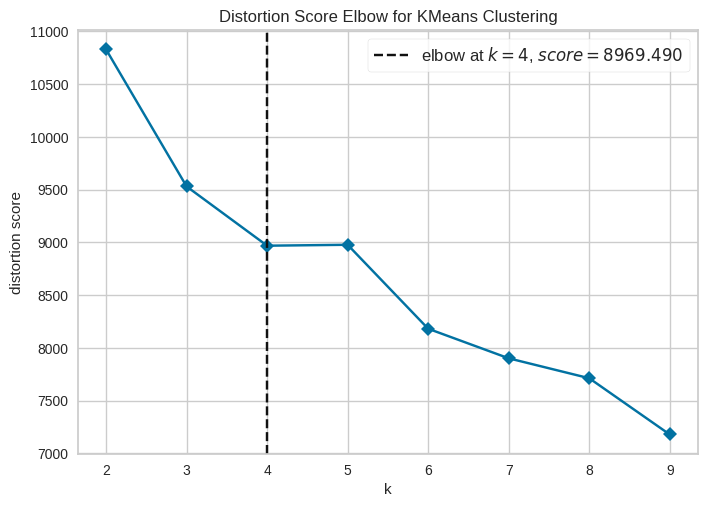

Jumlah cluster optimal: 4


In [ ]:
# Melakukan visualisasi Elbow Method menggunakan KElbowVisualizer()

### MULAI CODE ###

model_elbow = KMeans(random_state=42)
visualizer = KElbowVisualizer(model_elbow, k=(2, 10), timings=False)
visualizer.fit(df)
visualizer.show()

optimal_k = visualizer.elbow_value_
print(f'Jumlah cluster optimal: {optimal_k}')

### SELESAI CODE ###

In [ ]:
# Menggunakan algoritma K-Means Clustering

### MULAI CODE ###

n_clusters = optimal_k if optimal_k is not None else 3

model_clustering = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
model_clustering.fit(df)

df['Target'] = model_clustering.labels_
print(f'Distribusi cluster:\n{df["Target"].value_counts().sort_index()}')

### SELESAI CODE ###

Distribusi cluster:
Target
0    408
1    322
2    398
3    373
Name: count, dtype: int64


In [ ]:
# Menyimpan model menggunakan joblib

### MULAI CODE ###

joblib.dump(model_clustering, 'model_clustering.h5')
print('model_clustering.h5 berhasil disimpan')

### SELESAI CODE ###

model_clustering.h5 berhasil disimpan


## **Penilaian (Opsional)**

In [ ]:
# Menghitung dan menampilkan nilai Silhouette Score.

### MULAI CODE ###

X_cluster = df.drop(columns=['Target'])
sil_score = silhouette_score(X_cluster, df['Target'])
print(f'Silhouette Score (k={n_clusters}): {sil_score:.4f}')

### SELESAI CODE ###

Silhouette Score (k=4): 0.1356


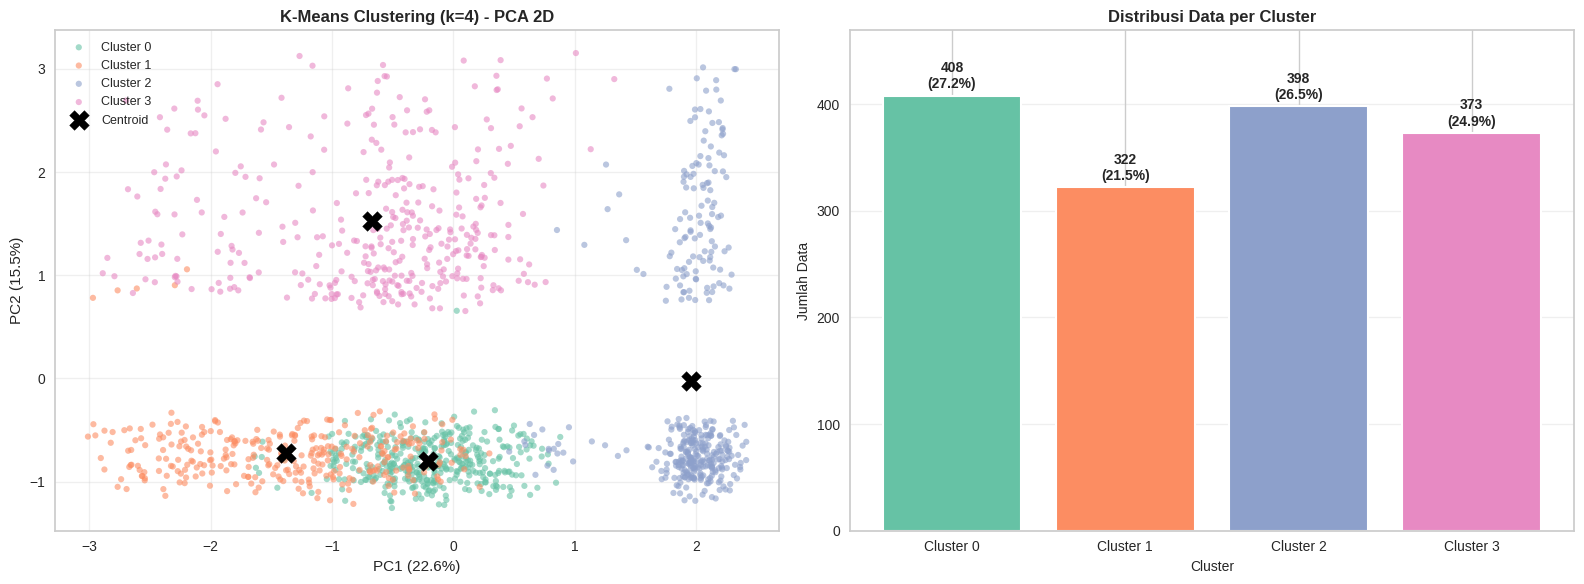

In [ ]:
# Membuat visualisasi hasil clustering

### MULAI CODE ###

pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_cluster)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = sns.color_palette('Set2', n_clusters)

for cluster_id in range(n_clusters):
    mask_c = df['Target'] == cluster_id
    axes[0].scatter(
        X_pca_2d[mask_c, 0], X_pca_2d[mask_c, 1],
        c=[colors[cluster_id]], label=f'Cluster {cluster_id}',
        alpha=0.6, s=20, edgecolors='none'
    )

centers_pca = pca_2d.transform(model_clustering.cluster_centers_)
axes[0].scatter(centers_pca[:, 0], centers_pca[:, 1],
                c='black', marker='X', s=200, zorder=5, label='Centroid')
axes[0].set_title(f'K-Means Clustering (k={n_clusters}) - PCA 2D', fontsize=12, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

cluster_counts = df['Target'].value_counts().sort_index()
bars = axes[1].bar(
    [f'Cluster {i}' for i in cluster_counts.index],
    cluster_counts.values,
    color=colors[:n_clusters], edgecolor='white', linewidth=1.5
)
for bar, val in zip(bars, cluster_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + max(cluster_counts.values)*0.01,
        f'{val:,}\n({val/len(df)*100:.1f}%)',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )
axes[1].set_title('Distribusi Data per Cluster', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Cluster', fontsize=10)
axes[1].set_ylabel('Jumlah Data', fontsize=10)
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim(0, max(cluster_counts.values) * 1.15)
plt.tight_layout()
plt.show()

### SELESAI CODE ###

In [ ]:
# Membangun model menggunakan PCA.

### MULAI CODE ###

pca_full = PCA(random_state=42)
pca_full.fit(X_cluster)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.argmax(cumvar >= 0.90) + 1)
print(f'Komponen PCA untuk 90% variance: {n_components}')

model = PCA(n_components=n_components, random_state=42)
X_pca = model.fit_transform(X_cluster)

kmeans_pca = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans_pca.fit(X_pca)

sil_pca = silhouette_score(X_pca, kmeans_pca.labels_)
print(f'Silhouette Score PCA K-Means : {sil_pca:.4f}')
print(f'Silhouette Score Original    : {sil_score:.4f}')

### SELESAI CODE ###

Komponen PCA untuk 90% variance: 7
Silhouette Score PCA K-Means : 0.1446
Silhouette Score Original    : 0.1356


In [ ]:
# Simpan model PCA sebagai perbandingan dengan menjalankan cell code ini
joblib.dump(model, 'PCA_model_clustering.h5')
print('PCA_model_clustering.h5 berhasil disimpan')

PCA_model_clustering.h5 berhasil disimpan


# **5. Interpretasi Hasil Clustering**
Menganalisis karakteristik tiap cluster berdasarkan statistik deskriptif.

In [ ]:
# Menampilkan analisis deskriptif minimal mean, min dan max untuk fitur numerik.
# Pastikan nama kolom clustering sudah diubah menjadi Target

### MULAI CODE ###

numeric_feat = [c for c in df.select_dtypes(include=[np.number]).columns if c != 'Target']
cluster_stats = df.groupby('Target')[numeric_feat].agg(['mean', 'min', 'max'])
print('Analisis Deskriptif per Cluster (mean, min, max):')
cluster_stats.round(3)

### SELESAI CODE ###

Analisis Deskriptif per Cluster (mean, min, max):


TransactionAmount               TransactionType           Location  \
                    mean    min    max            mean  min  max     mean   
Target                                                                      
0                 -0.587 -1.170  0.252             0.0  0.0  0.0   -0.026   
1                 -0.611 -1.172  0.439             0.0  0.0  0.0    0.048   
2                  0.011 -1.172  2.927             0.0  0.0  0.0   -0.024   
3                  1.158  0.231  3.035             0.0  0.0  0.0    0.013   

                     Channel  ... AccountBalance PreviousTransactionDate  \
          min    max    mean  ...            max                    mean   
Target                        ...                                          
0      -1.721  1.688  -0.005  ...          0.786                   0.035   
1      -1.721  1.688  -0.035  ...          2.560                   0.032   
2      -1.721  1.688   0.038  ...          1.206                  -0.036   
3      -1.721  1.688  -0.005  ...          2.569                  -0.027   

                     TransactionAmount_bin         TransactionType_bin          
          min    max                  mean min max                mean min max  
Target                                                                          
0      -1.762  1.752                 1.493   0   2                 0.0   0   0  
1      -1.722  1.752                 1.460   0   2                 0.0   0   0  
2      -1.752  1.752                 1.058   0   2                 0.0   0   0  
3      -1.752  1.761                 0.000   0   0                 0.0   0   0  

[4 rows x 36 columns]

In [ ]:
# Menjelaskan karakteristik tiap cluster berdasarkan hasil proses agregasi.

### MULAI CODE ###

cluster_means = df.groupby('Target')[numeric_feat].mean().round(3)
global_means  = df[numeric_feat].mean()

for cid in sorted(df['Target'].unique()):
    n_data = (df['Target'] == cid).sum()
    pct    = n_data / len(df) * 100
    print(f'\n=== Cluster {cid} ({n_data} data, {pct:.1f}%) ===')
    for feat in numeric_feat:
        val = cluster_means.loc[cid, feat]
        g   = global_means[feat]
        lvl = 'TINGGI' if val > g * 1.05 else ('RENDAH' if val < g * 0.95 else 'SEDANG')
        print(f'  {feat}: {val:.3f}  -> {lvl} (global mean: {g:.3f})')

### SELESAI CODE ###


=== Cluster 0 (408 data, 27.2%) ===
  TransactionAmount: -0.587  -> RENDAH (global mean: -0.000)
  TransactionType: 0.000  -> SEDANG (global mean: 0.000)
  Location: -0.026  -> RENDAH (global mean: -0.000)
  Channel: -0.005  -> RENDAH (global mean: 0.000)
  CustomerAge: 0.758  -> TINGGI (global mean: 0.000)
  CustomerOccupation: -0.035  -> RENDAH (global mean: -0.000)
  TransactionDuration: -0.028  -> RENDAH (global mean: -0.000)
  LoginAttempts: 0.000  -> SEDANG (global mean: 0.000)
  AccountBalance: -0.293  -> RENDAH (global mean: 0.000)
  PreviousTransactionDate: 0.035  -> TINGGI (global mean: -0.000)
  TransactionAmount_bin: 1.493  -> TINGGI (global mean: 0.999)
  TransactionType_bin: 0.000  -> SEDANG (global mean: 0.000)

=== Cluster 1 (322 data, 21.5%) ===
  TransactionAmount: -0.611  -> RENDAH (global mean: -0.000)
  TransactionType: 0.000  -> SEDANG (global mean: 0.000)
  Location: 0.048  -> TINGGI (global mean: -0.000)
  Channel: -0.035  -> RENDAH (global mean: 0.000)
  Custo

In [ ]:
# Simpan Data
# Mengekspor data training beserta data hasil clustering dengan kolom Target

### MULAI CODE ###

df.to_csv('data_clustering.csv', index=False)
print('data_clustering.csv berhasil disimpan')
print(f'Shape: {df.shape}')
df.head()

### SELESAI CODE ###

data_clustering.csv berhasil disimpan
Shape: (1501, 13)


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,TransactionAmount_bin,TransactionType_bin,Target
0,-1.107930,0.0,1.200869,-1.088615,1.444427,-1.316889,-0.537894,0.0,0.014221,-0.731171,1,0,0
1,0.579431,0.0,-0.503358,-1.088615,1.331694,-1.316889,0.304662,0.0,2.253155,0.122615,0,0,3
2,-0.585158,0.0,0.145871,1.361177,-1.430270,1.311635,-0.888959,0.0,-1.018894,-1.359244,2,0,2
3,-0.313941,0.0,0.957408,1.361177,-1.035703,1.311635,-1.324280,0.0,0.909321,-0.161981,2,0,2
4,-0.744226,0.0,0.551640,-1.088615,-1.486636,1.311635,0.739983,0.0,-1.107106,-1.634026,1,0,2


## **Penilaian (Opsional)**

In [ ]:
# inverse dataset ke rentang normal untuk numerikal

### MULAI CODE ###

df_inverse = df.copy()

scale_cols = [c for c in numeric_feat
              if '_bin' not in c and c in scaler.feature_names_in_]
print(f'Kolom yang di-inverse scale: {scale_cols}')
df_inverse[scale_cols] = scaler.inverse_transform(df_inverse[scale_cols])

### SELESAI CODE ###

Kolom yang di-inverse scale: ['TransactionAmount', 'TransactionType', 'Location', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'PreviousTransactionDate']


In [ ]:
# inverse dataset yang sudah diencode ke kategori aslinya.

### MULAI CODE ###

for col, le in label_encoders.items():
    if col in df_inverse.columns:
        try:
            df_inverse[col] = le.inverse_transform(df_inverse[col].astype(int))
        except Exception as e:
            print(f'  Skip inverse {col}: {e}')

df_inverse.head()

### SELESAI CODE ###

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,TransactionAmount_bin,TransactionType_bin,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08,Low,nan,0
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35,High,nan,3
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04,Medium,nan,2
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06,Medium,nan,2
4,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,2024-11-04 08:06:36,Low,nan,2


In [ ]:
# Lakukan analisis deskriptif minimal mean, min dan max untuk fitur numerik
# dan mode untuk kategorikal seperti pada basic tetapi menggunakan data yang sudah diinverse.

### MULAI CODE ###

# Fitur Numerik
num_inv = [c for c in df_inverse.select_dtypes(include=[np.number]).columns if c != 'Target']
print('=== Analisis Deskriptif Fitur Numerik (data inverse) ===')
display(df_inverse.groupby('Target')[num_inv].agg(['mean', 'min', 'max']).round(2))

# Fitur Kategorikal
cat_inv = df_inverse.select_dtypes(include=['object']).columns.tolist()
if cat_inv:
    print('\n=== Analisis Deskriptif Fitur Kategorikal (mode) ===')
    for col in cat_inv:
        mode_per_cluster = df_inverse.groupby('Target')[col].agg(
            lambda x: x.value_counts().index[0]
        )
        print(f'\n[{col}] Mode per cluster:')
        print(mode_per_cluster.to_string())

### SELESAI CODE ###

=== Analisis Deskriptif Fitur Numerik (data inverse) ===


TransactionAmount                 CustomerAge              \
                    mean     min     max        mean   min   max   
Target                                                             
0                 125.88    0.84  305.92       57.83  26.0  80.0   
1                 120.66    0.32  346.12       45.71  26.0  70.0   
2                 254.19    0.26  880.04       23.17  18.0  28.0   
3                 500.51  301.56  903.19       51.13  20.0  80.0   

       TransactionDuration              LoginAttempts            \
                      mean   min    max          mean  min  max   
Target                                                            
0                   117.29  12.0  298.0           1.0  1.0  1.0   
1                   120.84  10.0  300.0           1.0  1.0  1.0   
2                   121.01  11.0  299.0           1.0  1.0  1.0   
3                   118.38  10.0  296.0           1.0  1.0  1.0   

       AccountBalance                     
                 mean      min       max  
Target                                    
0             3924.61   112.76   8092.94  
1             9390.71  4401.78  14942.78  
2             1464.98   102.20   9716.68  
3             6388.42   135.96  14977.99


=== Analisis Deskriptif Fitur Kategorikal (mode) ===

[TransactionType] Mode per cluster:
Target
0    Debit
1    Debit
2    Debit
3    Debit

[Location] Mode per cluster:
Target
0    Chicago
1      Omaha
2    Chicago
3    Chicago

[Channel] Mode per cluster:
Target
0    ATM
1    ATM
2    ATM
3    ATM

[CustomerOccupation] Mode per cluster:
Target
0     Retired
1      Doctor
2     Student
3    Engineer

[PreviousTransactionDate] Mode per cluster:
Target
0    2024-11-04 08:06:23
1    2024-11-04 08:07:19
2    2024-11-04 08:08:30
3    2024-11-04 08:07:31

[TransactionAmount_bin] Mode per cluster:
Target
0       Low
1       Low
2    Medium
3      High

[TransactionType_bin] Mode per cluster:
Target
0    nan
1    nan
2    nan
3    nan


In [ ]:
# Periksa kembali data yang telah di-inverse.

### MULAI CODE ###

print(f'Shape     : {df_inverse.shape}')
print(f'Kolom     : {df_inverse.columns.tolist()}')
print(f'Tipe data :\n{df_inverse.dtypes}')
df_inverse.head()

### SELESAI CODE ###

Shape     : (1501, 13)
Kolom     : ['TransactionAmount', 'TransactionType', 'Location', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'PreviousTransactionDate', 'TransactionAmount_bin', 'TransactionType_bin', 'Target']
Tipe data :
TransactionAmount          float64
TransactionType             object
Location                    object
Channel                     object
CustomerAge                float64
CustomerOccupation          object
TransactionDuration        float64
LoginAttempts              float64
AccountBalance             float64
PreviousTransactionDate     object
TransactionAmount_bin       object
TransactionType_bin         object
Target                       int32
dtype: object


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,TransactionAmount_bin,TransactionType_bin,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08,Low,nan,0
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35,High,nan,3
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04,Medium,nan,2
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06,Medium,nan,2
4,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,2024-11-04 08:06:36,Low,nan,2


In [ ]:
# Simpan Data Inverse

### MULAI CODE ###

df_inverse.to_csv('data_clustering_inverse.csv', index=False)
print('data_clustering_inverse.csv berhasil disimpan')
print(f'Shape            : {df_inverse.shape}')
print(f'Kolom Target ada : {"Target" in df_inverse.columns}')
df_inverse.head()

### SELESAI CODE ###

data_clustering_inverse.csv berhasil disimpan
Shape            : (1501, 13)
Kolom Target ada : True


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,TransactionAmount_bin,TransactionType_bin,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08,Low,nan,0
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35,High,nan,3
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04,Medium,nan,2
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06,Medium,nan,2
4,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,2024-11-04 08:06:36,Low,nan,2


# **End of Notebook**